# 02. ユニバースを絞る

`regression_returns` / `quantile_returns` の `stocks=` に「月 `ym` → 銘柄 (bid) のリスト」を返す関数を渡すと、
その月末のエクスポージャーを使う翌月の全営業日で、計算対象をその銘柄に絞ります。

ここでは MSCI EM の NAM ファクター（AI / Revision / GEMQ3）を 3 通りのユニバースで計算します。

In [1]:
import pandas as pd

from p_ken import charts, factors, io
from p_ken.report import NAM_COLORS
from p_ken.stats import annualized

START, END = "2026-01-01", "2026-09-30"  # 計算期間（年初来）
Q_START = "2026-07-01"  # 強調する四半期の初日
HIGHLIGHT = (Q_START, END)


def pct(x):
    """表示用：小数のリターンを +1.23% 形式の文字列に。"""
    return x.map("{:+.2%}".format)

## 1. ユニバースを返す関数

`io.load_universe("gemq", ym)` は ym 月末のユニバース構成銘柄（bid, sedol, weight, ...）です。
bid の先頭 3 文字は上場国です。

In [2]:
def china(ym: str) -> list[str]:  # 上場国が中国・香港
    unv = io.load_universe("gemq", ym)
    return unv.loc[unv.bid.str[:3].isin(["CHN", "HKG"]), "bid"].tolist()


def top300(ym: str) -> list[str]:  # 指数ウェイト上位 300
    return io.load_universe("gemq", ym).nlargest(300, "weight").bid.tolist()


def ex_china(ym: str) -> list[str]:  # 中国・香港を除く
    unv = io.load_universe("gemq", ym)
    return unv.loc[~unv.bid.str[:3].isin(["CHN", "HKG"]), "bid"].tolist()


UNIVERSES = {"China": china, "Top 300": top300, "ex China": ex_china}

各月の銘柄数を確認します（ym 月末のユニバースが、翌月のリターン計算に使われます）。

In [3]:
yms = [ym for ym in io.list_yms("gemq", "universe") if "202512" <= ym <= "202608"]
pd.DataFrame(
    {
        "All": [len(io.load_universe("gemq", ym)) for ym in yms],
        **{name: [len(fn(ym)) for ym in yms] for name, fn in UNIVERSES.items()},
    },
    index=pd.Index(yms, name="ym"),
)

,All,China,Top 300,ex China
ym,,,,
202512,1196,550,300,646
202601,1195,550,300,645
202602,1205,573,300,632
202603,1204,572,300,632
202604,1204,572,300,632
202605,1178,568,300,610
202606,1178,568,300,610
202607,1178,568,300,610
202608,1167,569,300,598


## 2. ファクターリターン

`nam_exposures("gemq")` はレポートと同じエクスポージャー（前月末の AI / Revision / GEMQ3）です。

In [4]:
exposures = factors.nam_exposures("gemq")
results = {"All": factors.regression_returns("gemq", exposures, START, END)}
for name, stocks in UNIVERSES.items():
    results[name] = factors.regression_returns("gemq", exposures, START, END, stocks=stocks)

# 四半期の合計（行 = ファクター、列 = ユニバース）
pct(pd.DataFrame({name: d.loc[Q_START:].sum() for name, d in results.items()}))

,All,China,Top 300,ex China
AI,-1.65%,-3.76%,-0.84%,-0.01%
Revision,+0.84%,-1.01%,+0.63%,+2.00%
GEMQ3,-0.61%,-2.95%,+0.82%,+1.67%


## 3. AI ファクターをユニバース別に比較

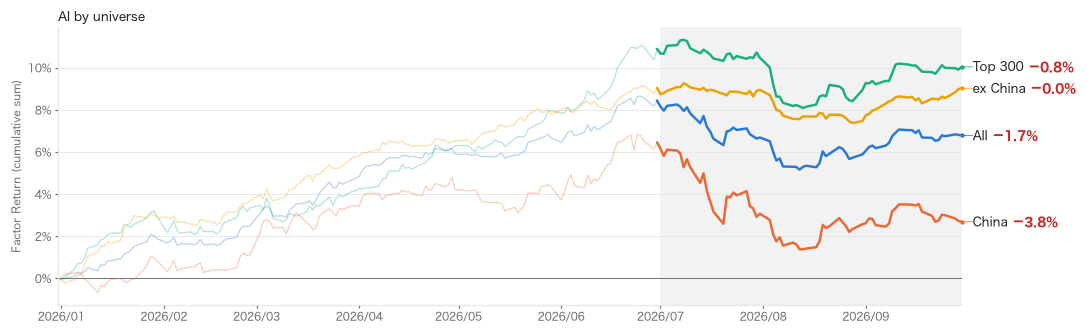

In [5]:
ai = pd.DataFrame({name: d["AI"] for name, d in results.items()})
fig = charts.plot_cumulative(ai, START, HIGHLIGHT, "AI by universe", dpi=110)